In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.plotting import scatter_matrix
from scipy.stats import loguniform, randint, uniform
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import (GradientBoostingRegressor,
                              HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import (RandomizedSearchCV, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
data = pd.read_csv("data/vehicle/CAR DETAILS FROM CAR DEKHO.csv")

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB


In [4]:
data

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
...,...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner


In [5]:
data["brand"] = data["name"].str.split().str[0]
data.pop("name")

0                             Maruti 800 AC
1                  Maruti Wagon R LXI Minor
2                      Hyundai Verna 1.6 SX
3                    Datsun RediGO T Option
4                     Honda Amaze VX i-DTEC
                       ...                 
4335    Hyundai i20 Magna 1.4 CRDi (Diesel)
4336             Hyundai i20 Magna 1.4 CRDi
4337                    Maruti 800 AC BSIII
4338       Hyundai Creta 1.6 CRDi SX Option
4339                       Renault KWID RXT
Name: name, Length: 4340, dtype: str

In [7]:
X = data.drop("selling_price", axis=1)
y = data["selling_price"]

In [8]:
data["year"] = 2024 - data["year"]

In [9]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
attributes = ["year", "selling_price", "km_driven"]

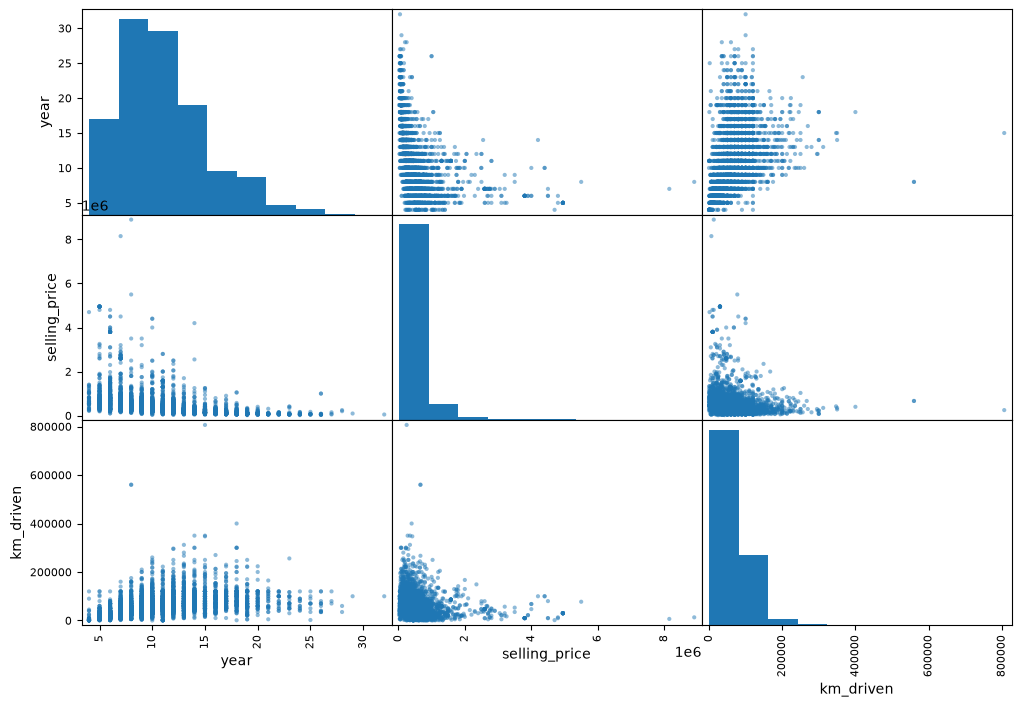

In [11]:
scatter_matrix(data[attributes], figsize=(12, 8))
plt.show()

In [12]:
km_log = np.log(data["km_driven"])
selling_price = np.log(data["selling_price"])

(array([   6.,   92.,  414.,  740., 1222., 1232.,  454.,  113.,   53.,
          14.]),
 array([ 9.90348755, 10.51329498, 11.12310241, 11.73290984, 12.34271727,
        12.95252469, 13.56233212, 14.17213955, 14.78194698, 15.39175441,
        16.00156183]),
 <BarContainer object of 10 artists>)

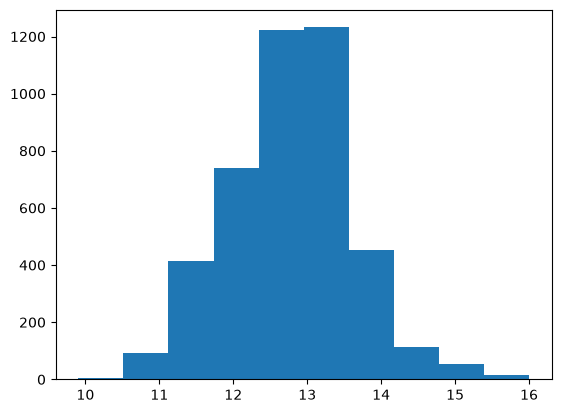

In [13]:
plt.hist(selling_price)

array([[<Axes: title={'center': 'year'}>,
        <Axes: title={'center': 'selling_price'}>],
       [<Axes: title={'center': 'km_driven'}>, <Axes: >]], dtype=object)

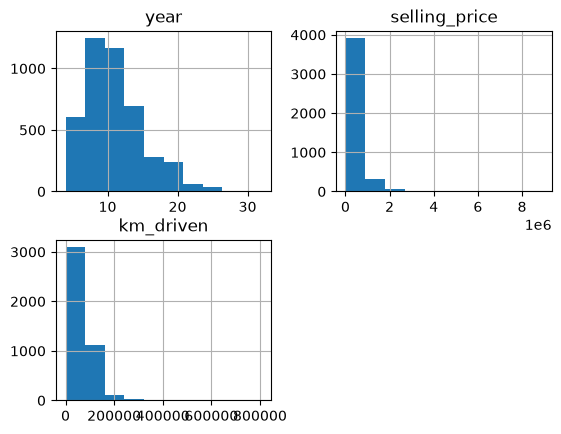

In [14]:
data.hist()

In [15]:
x_train.info()

<class 'pandas.DataFrame'>
Index: 3472 entries, 227 to 860
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   year          3472 non-null   int64 
 1   km_driven     3472 non-null   int64 
 2   fuel          3472 non-null   str   
 3   seller_type   3472 non-null   str   
 4   transmission  3472 non-null   str   
 5   owner         3472 non-null   str   
 6   brand         3472 non-null   object
dtypes: int64(2), object(1), str(4)
memory usage: 330.4+ KB


In [16]:
cat_attr = x_train.select_dtypes(include=[str,"object"]).columns
num_attr = x_train.select_dtypes(include=np.number).columns

In [17]:
cat_attr

Index(['fuel', 'seller_type', 'transmission', 'owner', 'brand'], dtype='str')

In [18]:
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_attr),
    ("num", StandardScaler(), num_attr),
])

# Examining Several Models

## Linear Regression

In [202]:
# Linear Regression
lr_model = TransformedTargetRegressor(
    regressor=LinearRegression(),
    func=np.log,
    inverse_func=np.exp,
)

full_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", lr_model),
])
full_pipeline.fit(x_train, y_train)

rmse_lr = -cross_val_score(
    estimator=full_pipeline,
    X=x_train,
    y=y_train,
    n_jobs=8,
    cv=10,
    scoring="neg_root_mean_squared_error"
)

pd.Series(rmse_lr).describe()

count        10.000000
mean     255377.825585
std       42933.793320
min      198046.307003
25%      239497.072079
50%      251809.113617
75%      272339.993102
max      350308.257546
dtype: float64

## Random Forest Regression

In [21]:
full_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestRegressor(random_state=42)),
])

full_pipeline.fit(x_train, y_train)

rmse = -cross_val_score(
    estimator=full_pipeline,
    X=x_train,
    y=y_train,
    n_jobs=8,
    cv=10,
    scoring="neg_root_mean_squared_error"
)

pd.Series(rmse).describe()

count        10.000000
mean     256415.231349
std       57990.850672
min      165833.356239
25%      218155.365364
50%      257615.364305
75%      289387.854629
max      357891.515031
dtype: float64

Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'model__l2_regularization': np.float64(0.345071248026683), 'model__learning_rate': np.float64(0.20030540341040914), 'model__max_depth': 5, 'model__max_iter': 152, 'model__max_leaf_nodes': 58, 'model__min_samples_leaf': 10, 'model__n_iter_no_change': 30, 'model__tol': 0.001, 'model__validation_fraction': 0.2}


## Hist Gradient Boosting Regression

In [ ]:
hgb_model = TransformedTargetRegressor(
    regressor=HistGradientBoostingRegressor(random_state=42),
    func=np.log,
    inverse_func=np.exp,
)

full_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", hgb_model),
])

full_pipeline.fit(x_train, y_train)

rmse = -cross_val_score(
    estimator=full_pipeline,
    X=x_train,
    y=y_train,
    n_jobs=8,
    cv=10,
    scoring="neg_root_mean_squared_error"
)

pd.Series(rmse).describe()

count        10.000000
mean     263801.295674
std       56231.978100
min      197733.704365
25%      211065.303109
50%      265744.540858
75%      309886.635269
max      353839.601144
dtype: float64

## Gradient Boosting Regression

In [20]:
# Gradient Boosting Regression

gb_model = TransformedTargetRegressor(
    regressor=GradientBoostingRegressor(random_state=42),
    func=np.log,
    inverse_func=np.exp,
)

full_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", gb_model),
])

full_pipeline.fit(x_train, y_train)

rmse = -cross_val_score(
    estimator=full_pipeline,
    X=x_train,
    y=y_train,
    n_jobs=8,
    cv=10,
    scoring="neg_root_mean_squared_error"
)

pd.Series(rmse).describe()

count        10.000000
mean     264696.810191
std       43196.405098
min      206879.431476
25%      234627.254869
50%      271546.788352
75%      289005.436923
max      343109.306278
dtype: float64

## Final Model

In [32]:
gb_model = TransformedTargetRegressor(
    regressor=GradientBoostingRegressor(random_state=42),
    func=np.log,
    inverse_func=np.exp,
)

full_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", gb_model),
])

full_pipeline.fit(x_train, y_train)

rmse = -cross_val_score(
    estimator=full_pipeline,
    X=x_train,
    y=y_train,
    n_jobs=8,
    cv=10,
    scoring="neg_root_mean_squared_error"
)

pd.Series(rmse).describe()

param_dist_gb = {
    "model__regressor__loss": ["squared_error", "absolute_error", "huber", "quantile"],
    "model__regressor__learning_rate" : loguniform(1e-2, 3e-1),
    "model__regressor__n_estimators": np.arange(70,500,step=30),
}

search = RandomizedSearchCV(
    full_pipeline, param_dist_gb,
    n_iter=30, cv=5, scoring="neg_root_mean_squared_error",
    n_jobs=8, random_state=42, verbose=1,
)
search.fit(x_train, y_train)
print(search.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'model__regressor__learning_rate': np.float64(0.1205712628744377), 'model__regressor__loss': 'squared_error', 'model__regressor__n_estimators': np.int64(190)}


In [42]:
best_model = search.best_estimator_
y_pred = best_model.predict(x_test)

rmse_test = root_mean_squared_error(y_test, y_pred)
print("Test RMSE:", rmse_test)
print("Best CV score:", -search.best_score_)

Test RMSE: 332258.1970972417
Best CV score: 259106.05178493442
